In [5]:
from langchain.chat_models import init_chat_model
from langchain_core.messages import AIMessage
from langgraph.constants import START, END
from langgraph.graph import MessagesState, StateGraph

# 1.定义模型
llm = init_chat_model(
    'deepseek-v4-flash',
    extra_body={'thinking': {'type': 'disabled'}}
)

In [6]:
# 2.定义State，记录用户输入、最终结果
class IntentState(MessagesState):
    intent: str

In [11]:
from typing import Literal


# 3.Node

def intent_node(state: IntentState):
    intent = llm.invoke(f'''
    根据用户的请求判断用户意图，可选意图：weather、translate或chat。
    user_query: {state['messages'][-1].content}
    ''')
    return {"intent": intent.text}


def weather_node(state: IntentState):
    return {"messages": [AIMessage("今天天气晴，25度，适合外出。")]}


def translate_node(state: IntentState):
    res = llm.invoke(f'''
    按照用户要求翻译，只输出翻译结果，不要任何解释。
    user_query: {state['messages'][-1].content}
    ''')
    return {"messages": [res]}


def chat_node(state: IntentState):
    res = llm.invoke(state['messages'])
    return {"messages": [res]}


def router(state: IntentState) -> Literal['weather', 'translate', 'chat']:
    return state["intent"]

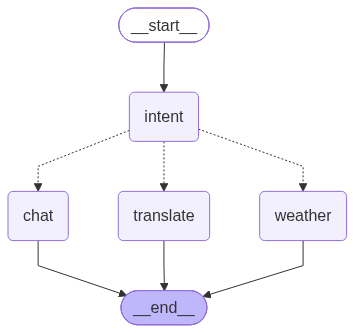

In [12]:
from IPython.core.display import Image

# 4. Edge
builder = StateGraph(IntentState)

builder.add_node("intent", intent_node)
builder.add_node("weather", weather_node)
builder.add_node("translate", translate_node)
builder.add_node("chat", chat_node)

builder.add_edge(START, "intent")
builder.add_conditional_edges("intent", router)
builder.add_edge("weather", END)
builder.add_edge("translate", END)
builder.add_edge("chat", END)

graph = builder.compile()

display(Image(graph.get_graph(xray=True).draw_mermaid_png()))

In [16]:
from langchain_core.messages import HumanMessage

for q in ['今天北京天气如何？', '翻译Tom is handsome', '你好']:
    r = graph.invoke({'messages': [HumanMessage(content=q)]})
    print(f"'{q}' -> intent={r['intent']} -> {r['messages'][-1].content}")

'今天北京天气如何？' -> intent=weather -> 今天天气晴，25度，适合外出。
'翻译Tom is handsome' -> intent=translate -> 汤姆很帅
'你好' -> intent=chat -> 你好！很高兴见到你，有什么我可以帮忙的吗？
